# Deteksi Trafik Malicious DoH sebagai Proof of Concept Deteksi Eksfiltrasi Data Berbasis Metadata Flow

Notebook ini menjalankan pipeline eksperimen machine learning untuk dataset `BCCC-CIRA-CIC-DoHBrw-2020.csv` menggunakan fitur numerik metadata flow. Fokus eksperimen: load dataset, inspeksi, cleaning, deteksi label, training model klasik, evaluasi metrik deteksi, analisis threshold, simulasi alert SOC sederhana, dan penyimpanan artefak eksperimen.

Artefak disimpan ke folder `../outputs/` bila notebook dijalankan dari folder `notebooks/`, atau `outputs/` bila dijalankan dari root repository.

Notebook ini merupakan eksperimen offline menggunakan dataset publik. Hasil klasifikasi malicious DoH digunakan sebagai proof of concept untuk mendukung rancangan deteksi eksfiltrasi data pada lingkungan SOC. Notebook ini belum merepresentasikan sistem SOC real-time dan belum diuji pada trafik operasional nyata.

## 1. Setup dan Konfigurasi

In [1]:
import json
import time
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.ensemble import AdaBoostClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    auc,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, StandardScaler

warnings.filterwarnings("ignore")
try:
    plt.style.use("seaborn-v0_8-whitegrid")
except OSError:
    plt.style.use("default")

RANDOM_STATE = 42
TEST_SIZE = 0.2

DATA_CANDIDATES = [
    Path("../data/BCCC-CIRA-CIC-DoHBrw-2020.csv"),
    Path("data/BCCC-CIRA-CIC-DoHBrw-2020.csv"),
]
OUTPUT_CANDIDATES = [Path("../outputs"), Path("outputs")]

DATA_PATH = next((path for path in DATA_CANDIDATES if path.exists()), DATA_CANDIDATES[0])
OUTPUT_DIR = OUTPUT_CANDIDATES[0] if DATA_CANDIDATES[0].exists() else OUTPUT_CANDIDATES[1]
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"Dataset path : {DATA_PATH.resolve()}")
print(f"Output dir   : {OUTPUT_DIR.resolve()}")

Dataset path : D:\Skripsi\doh_exfiltration_skripsi\data\BCCC-CIRA-CIC-DoHBrw-2020.csv
Output dir   : D:\Skripsi\doh_exfiltration_skripsi\outputs


## 2. Load Dataset

In [2]:
df_raw = pd.read_csv(DATA_PATH)
df_raw.columns = df_raw.columns.str.strip()

print(f"Shape dataset: {df_raw.shape}")
display(df_raw.head())

Shape dataset: (499106, 29)


,FlowBytesSent,FlowSentRate,FlowBytesReceived,FlowReceivedRate,PacketLengthVariance,PacketLengthStandardDeviation,PacketLengthMean,PacketLengthMedian,PacketLengthMode,PacketLengthSkewFromMedian,...,PacketTimeCoefficientofVariation,ResponseTimeTimeVariance,ResponseTimeTimeStandardDeviation,ResponseTimeTimeMean,ResponseTimeTimeMedian,ResponseTimeTimeMode,ResponseTimeTimeSkewFromMedian,ResponseTimeTimeSkewFromMode,ResponseTimeTimeCoefficientofVariation,Label
0,353,80.890348,393,90.056393,469.209877,21.661253,82.888889,66.0,66,2.339046,...,0.534524,1.754601e-09,0.000042,0.000048,0.000019,0.000017,2.028699,0.737490,0.869641,Benign
1,1807,53.056709,4828,141.758602,145520.370987,381.471324,228.793103,76.0,68,1.201609,...,1.591559,5.348911e-05,0.007314,0.011523,0.015273,0.000016,-1.538407,1.573304,0.634722,Malicious
2,15000,479.536009,27719,886.150575,25949.480963,161.088426,135.186709,87.0,87,0.897396,...,0.670950,3.356292e-01,0.579335,0.139518,0.001976,0.000003,0.712241,0.240819,4.152404,Malicious
3,1755,58.193065,4617,153.125406,154088.445853,392.541007,245.112953,75.5,54,1.296268,...,2.029971,1.245935e+02,11.162146,5.011613,0.015778,0.012884,1.342708,0.447829,2.227258,Benign
4,618,3.491495,315,1.779646,319.410000,17.872045,93.300000,105.0,105,-1.963961,...,0.816362,2.975575e-09,0.000054,0.015507,0.015471,0.015466,1.986391,0.751146,0.003502,Benign


## 3. Inspeksi Awal Dataset

In [3]:
inspection_summary = pd.DataFrame({
    "dtype": df_raw.dtypes.astype(str),
    "missing": df_raw.isna().sum(),
    "missing_pct": (df_raw.isna().mean() * 100).round(3),
    "unique": df_raw.nunique(dropna=True),
})

print("Ringkasan kolom:")
display(inspection_summary)

print(f"Duplikasi baris: {df_raw.duplicated().sum():,}")
display(df_raw.describe(include="all").T)

Ringkasan kolom:


,dtype,missing,missing_pct,unique
FlowBytesSent,int64,0,0.0,92881
FlowSentRate,float64,0,0.0,473663
FlowBytesReceived,int64,0,0.0,97046
FlowReceivedRate,float64,0,0.0,475526
PacketLengthVariance,float64,0,0.0,204248
PacketLengthStandardDeviation,float64,0,0.0,204015
PacketLengthMean,float64,0,0.0,196341
PacketLengthMedian,float64,0,0.0,32083
PacketLengthMode,int64,0,0.0,165
PacketLengthSkewFromMedian,float64,0,0.0,203906


Duplikasi baris: 7,115


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
FlowBytesSent,499106.0,NaN,NaN,NaN,40200.925483,143961.65579,55.0,618.0,1807.0,5542.0,8015359.0
FlowSentRate,499106.0,NaN,NaN,NaN,47339.147444,421275.12888,1.464903,54.107811,364.096931,3810.259664,23043478.26087
FlowBytesReceived,499106.0,NaN,NaN,NaN,42501.556227,139392.708614,54.0,476.0,4827.0,7888.0,7723184.0
FlowReceivedRate,499106.0,NaN,NaN,NaN,31668.292337,256680.472304,1.576245,141.812836,461.114551,4215.497773,7600000.0
PacketLengthVariance,499106.0,NaN,NaN,NaN,92635.84963,153493.758127,0.0,469.209877,18267.886503,141598.912222,1578115.36
PacketLengthStandardDeviation,499106.0,NaN,NaN,NaN,220.169083,210.141825,0.0,21.661253,135.142971,376.296309,1256.230616
PacketLengthMean,499106.0,NaN,NaN,NaN,173.159814,85.50649,56.0,92.0,152.488283,228.758621,689.8
PacketLengthMedian,499106.0,NaN,NaN,NaN,95.472702,32.99974,54.0,76.0,87.0,105.0,317.0
PacketLengthMode,499106.0,NaN,NaN,NaN,70.749953,14.830277,54.0,66.0,68.0,68.0,553.0
PacketLengthSkewFromMedian,499106.0,NaN,NaN,NaN,0.442934,1.551998,-10.0,0.199848,0.986397,1.201609,2.932375


## 4. Deteksi Kolom Label

In [4]:
def detect_label_column(dataframe: pd.DataFrame) -> str:
    explicit_candidates = ["Label", "label", "Class", "class", "Target", "target", "Category", "category"]
    for candidate in explicit_candidates:
        if candidate in dataframe.columns:
            return candidate

    object_columns = dataframe.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
    low_cardinality = [col for col in object_columns if 1 < dataframe[col].nunique(dropna=True) <= 20]
    if low_cardinality:
        return low_cardinality[-1]

    raise ValueError("Kolom label tidak ditemukan. Tambahkan nama label ke explicit_candidates.")


LABEL_COL = detect_label_column(df_raw)

print(f"Kolom label terdeteksi: {LABEL_COL}")
display(df_raw[LABEL_COL].value_counts(dropna=False).rename("count").to_frame())

Kolom label terdeteksi: Label


,count
Label,
Benign,249553
Malicious,249553


## 5. Cleaning dan Seleksi Fitur Numerik Metadata Flow

In [5]:
df = df_raw.copy()
initial_rows = len(df)

df = df.replace([np.inf, -np.inf], np.nan)
df = df.dropna(subset=[LABEL_COL])
df = df.drop_duplicates().reset_index(drop=True)

numeric_features = df.drop(columns=[LABEL_COL]).select_dtypes(include=[np.number]).columns.tolist()
constant_features = [col for col in numeric_features if df[col].nunique(dropna=True) <= 1]
numeric_features = [col for col in numeric_features if col not in constant_features]

X = df[numeric_features].copy()
y_raw = df[LABEL_COL].astype(str).str.strip()

label_encoder = LabelEncoder()
encoded_all = label_encoder.fit_transform(y_raw)
classes = label_encoder.classes_.tolist()

if len(classes) != 2:
    raise ValueError(f"Pipeline ini disiapkan untuk klasifikasi biner. Kelas ditemukan: {classes}")

positive_keywords = ["malicious", "attack", "exfil", "tunnel", "botnet"]
positive_class = next(
    (cls for cls in classes if any(keyword in cls.lower() for keyword in positive_keywords)),
    classes[1],
)
negative_class = next(cls for cls in classes if cls != positive_class)
y = (y_raw == positive_class).astype(int)

cleaning_summary = {
    "initial_rows": int(initial_rows),
    "rows_after_cleaning": int(len(df)),
    "removed_rows": int(initial_rows - len(df)),
    "label_column": LABEL_COL,
    "negative_class_0": negative_class,
    "positive_class_1": positive_class,
    "n_numeric_features": int(len(numeric_features)),
    "constant_features_removed": constant_features,
}

print(json.dumps(cleaning_summary, indent=2))
display(X.head())

{
  "initial_rows": 499106,
  "rows_after_cleaning": 491991,
  "removed_rows": 7115,
  "label_column": "Label",
  "negative_class_0": "Benign",
  "positive_class_1": "Malicious",
  "n_numeric_features": 28,
  "constant_features_removed": []
}


,FlowBytesSent,FlowSentRate,FlowBytesReceived,FlowReceivedRate,PacketLengthVariance,PacketLengthStandardDeviation,PacketLengthMean,PacketLengthMedian,PacketLengthMode,PacketLengthSkewFromMedian,...,PacketTimeSkewFromMode,PacketTimeCoefficientofVariation,ResponseTimeTimeVariance,ResponseTimeTimeStandardDeviation,ResponseTimeTimeMean,ResponseTimeTimeMedian,ResponseTimeTimeMode,ResponseTimeTimeSkewFromMedian,ResponseTimeTimeSkewFromMode,ResponseTimeTimeCoefficientofVariation
0,353,80.890348,393,90.056393,469.209877,21.661253,82.888889,66.0,66,2.339046,...,1.870823,0.534524,1.754601e-09,0.000042,0.000048,0.000019,0.000017,2.028699,0.737490,0.869641
1,1807,53.056709,4828,141.758602,145520.370987,381.471324,228.793103,76.0,68,1.201609,...,0.628315,1.591559,5.348911e-05,0.007314,0.011523,0.015273,0.000016,-1.538407,1.573304,0.634722
2,15000,479.536009,27719,886.150575,25949.480963,161.088426,135.186709,87.0,87,0.897396,...,1.490425,0.670950,3.356292e-01,0.579335,0.139518,0.001976,0.000003,0.712241,0.240819,4.152404
3,1755,58.193065,4617,153.125406,154088.445853,392.541007,245.112953,75.5,54,1.296268,...,0.488805,2.029971,1.245935e+02,11.162146,5.011613,0.015778,0.012884,1.342708,0.447829,2.227258
4,618,3.491495,315,1.779646,319.410000,17.872045,93.300000,105.0,105,-1.963961,...,1.224947,0.816362,2.975575e-09,0.000054,0.015507,0.015471,0.015466,1.986391,0.751146,0.003502


## 6. Split Data Train-Test

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y,
)

print(f"Train shape: {X_train.shape}")
print(f"Test shape : {X_test.shape}")
print("Distribusi label train:")
display(y_train.value_counts(normalize=True).rename({0: negative_class, 1: positive_class}).to_frame("ratio"))
print("Distribusi label test:")
display(y_test.value_counts(normalize=True).rename({0: negative_class, 1: positive_class}).to_frame("ratio"))

Train shape: (393592, 28)
Test shape : (98399, 28)
Distribusi label train:


,ratio
Label,
Malicious,0.5072
Benign,0.4928


Distribusi label test:


,ratio
Label,
Malicious,0.5072
Benign,0.4928


## 7. Training Model: Logistic Regression, Random Forest, dan AdaBoost

In [7]:
models = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE)),
    ]),
    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            random_state=RANDOM_STATE,
            class_weight="balanced",
            n_jobs=-1,
        )),
    ]),
    "AdaBoost": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("classifier", AdaBoostClassifier(
            n_estimators=200,
            learning_rate=0.5,
            random_state=RANDOM_STATE,
        )),
    ]),
}

trained_models = {}
train_times = {}

for model_name, model in models.items():
    start_time = time.perf_counter()
    model.fit(X_train, y_train)
    train_times[model_name] = time.perf_counter() - start_time
    trained_models[model_name] = model
    print(f"{model_name} selesai dilatih dalam {train_times[model_name]:.4f} detik")

Logistic Regression selesai dilatih dalam 4.5046 detik
Random Forest selesai dilatih dalam 101.8254 detik
AdaBoost selesai dilatih dalam 254.2349 detik


## 8. Evaluasi Model

In [8]:
def get_positive_scores(model, features: pd.DataFrame) -> np.ndarray:
    if hasattr(model, "predict_proba"):
        return model.predict_proba(features)[:, 1]
    if hasattr(model, "decision_function"):
        scores = model.decision_function(features)
        return (scores - scores.min()) / (scores.max() - scores.min())
    return model.predict(features)


def evaluate_binary_classifier(model_name: str, model, X_eval: pd.DataFrame, y_eval: pd.Series) -> dict:
    start_time = time.perf_counter()
    y_score = get_positive_scores(model, X_eval)
    y_pred = (y_score >= 0.5).astype(int)
    inference_time = time.perf_counter() - start_time

    tn, fp, fn, tp = confusion_matrix(y_eval, y_pred, labels=[0, 1]).ravel()
    fpr_value = fp / (fp + tn) if (fp + tn) else 0.0
    throughput = len(X_eval) / inference_time if inference_time > 0 else np.inf

    return {
        "model": model_name,
        "accuracy": accuracy_score(y_eval, y_pred),
        "precision": precision_score(y_eval, y_pred, zero_division=0),
        "recall_tpr": recall_score(y_eval, y_pred, zero_division=0),
        "f1_score": f1_score(y_eval, y_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_eval, y_score),
        "fpr": fpr_value,
        "training_time_sec": train_times[model_name],
        "inference_time_sec": inference_time,
        "throughput_rows_per_sec": throughput,
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp),
        "y_score": y_score,
        "y_pred": y_pred,
    }


evaluation_records = [
    evaluate_binary_classifier(model_name, model, X_test, y_test)
    for model_name, model in trained_models.items()
]

metrics_columns = [
    "model", "accuracy", "precision", "recall_tpr", "f1_score", "roc_auc", "fpr",
    "training_time_sec", "inference_time_sec", "throughput_rows_per_sec", "tn", "fp", "fn", "tp",
]
metrics_df = pd.DataFrame(evaluation_records)[metrics_columns].sort_values(
    by=["roc_auc", "f1_score", "recall_tpr"], ascending=False
).reset_index(drop=True)

display(metrics_df)

,model,accuracy,precision,recall_tpr,f1_score,roc_auc,fpr,training_time_sec,inference_time_sec,throughput_rows_per_sec,tn,fp,fn,tp
0,Random Forest,0.999868,0.999960,0.999780,0.999870,0.999999,0.000041,101.825352,0.340237,2.892076e+05,48489,2,11,49897
1,AdaBoost,0.998262,0.998597,0.997976,0.998286,0.999961,0.001444,254.234877,1.838121,5.353239e+04,48421,70,101,49807
2,Logistic Regression,0.901361,0.873222,0.942334,0.906463,0.958280,0.140810,4.504594,0.051862,1.897338e+06,41663,6828,2878,47030


## 9. Confusion Matrix

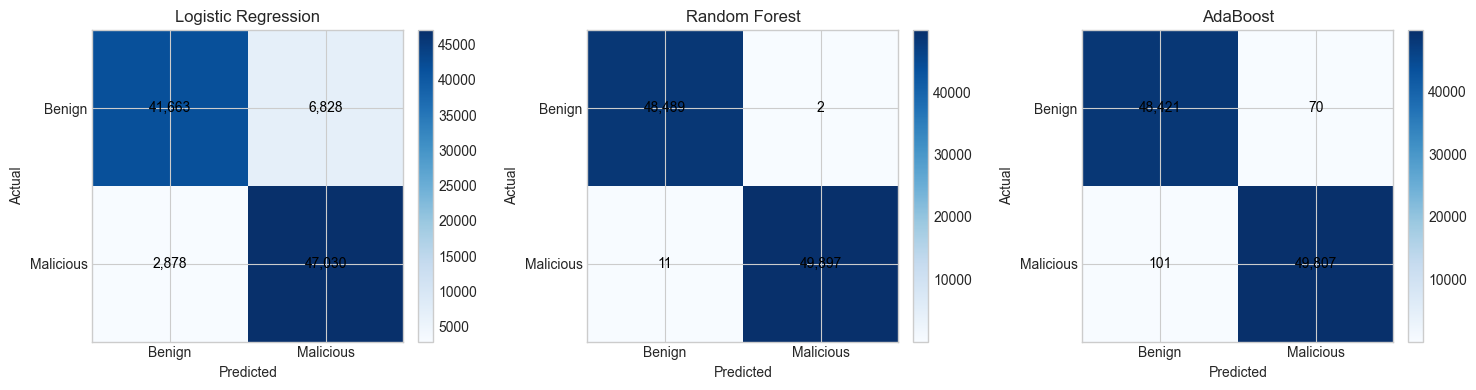

Saved: D:\Skripsi\doh_exfiltration_skripsi\outputs\confusion_matrices.png


In [9]:
fig, axes = plt.subplots(1, len(evaluation_records), figsize=(5 * len(evaluation_records), 4))
if len(evaluation_records) == 1:
    axes = [axes]

for ax, record in zip(axes, evaluation_records):
    cm = np.array([[record["tn"], record["fp"]], [record["fn"], record["tp"]]])
    image = ax.imshow(cm, cmap="Blues")
    ax.set_xticks([0, 1], labels=[negative_class, positive_class])
    ax.set_yticks([0, 1], labels=[negative_class, positive_class])
    for row in range(cm.shape[0]):
        for col in range(cm.shape[1]):
            ax.text(col, row, f"{cm[row, col]:,}", ha="center", va="center", color="black")
    fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
    ax.set_title(record["model"])
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
confusion_matrix_path = OUTPUT_DIR / "confusion_matrices.png"
plt.savefig(confusion_matrix_path, dpi=160, bbox_inches="tight")
plt.show()
print(f"Saved: {confusion_matrix_path.resolve()}")

## 10. ROC Curve

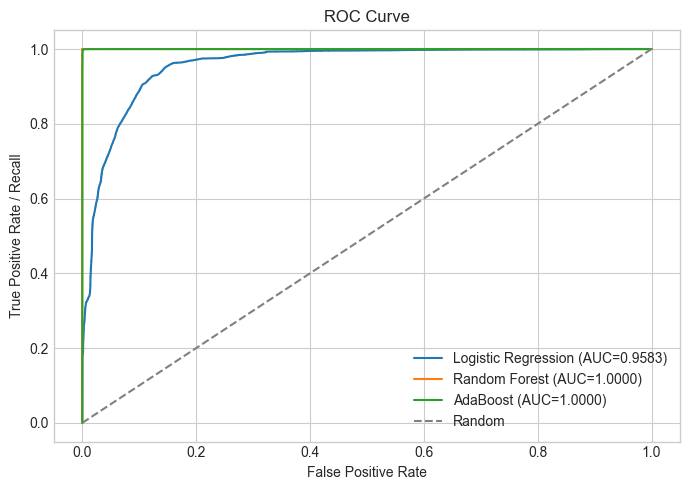

Saved: D:\Skripsi\doh_exfiltration_skripsi\outputs\roc_curve.png


In [10]:
plt.figure(figsize=(7, 5))
roc_curves = {}

for record in evaluation_records:
    fpr_values, tpr_values, thresholds = roc_curve(y_test, record["y_score"])
    roc_curves[record["model"]] = {
        "fpr": fpr_values,
        "tpr": tpr_values,
        "thresholds": thresholds,
        "auc": auc(fpr_values, tpr_values),
    }
    plt.plot(fpr_values, tpr_values, label=f"{record['model']} (AUC={roc_curves[record['model']]['auc']:.4f})")

plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate / Recall")
plt.title("ROC Curve")
plt.legend(loc="lower right")
plt.tight_layout()
roc_curve_path = OUTPUT_DIR / "roc_curve.png"
plt.savefig(roc_curve_path, dpi=160, bbox_inches="tight")
plt.show()
print(f"Saved: {roc_curve_path.resolve()}")

## 11. Feature Importance Random Forest

,feature,importance
0,PacketLengthMode,0.225193
1,PacketLengthMean,0.099191
2,PacketLengthStandardDeviation,0.066940
3,FlowBytesReceived,0.059222
4,PacketTimeStandardDeviation,0.057700
5,PacketTimeVariance,0.055624
6,PacketLengthMedian,0.052119
7,FlowBytesSent,0.045637
8,PacketLengthCoefficientofVariation,0.043203
9,PacketLengthVariance,0.039397


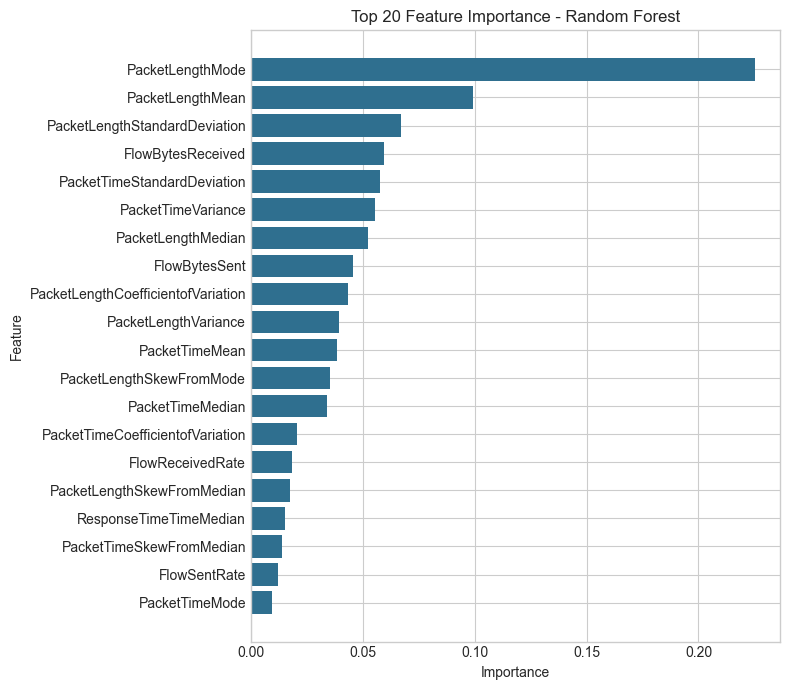

Saved: D:\Skripsi\doh_exfiltration_skripsi\outputs\random_forest_feature_importance.png


In [11]:
rf_model = trained_models["Random Forest"]
rf_classifier = rf_model.named_steps["classifier"]

feature_importance_df = pd.DataFrame({
    "feature": numeric_features,
    "importance": rf_classifier.feature_importances_,
}).sort_values("importance", ascending=False).reset_index(drop=True)

display(feature_importance_df)

top_features = feature_importance_df.head(20).sort_values("importance")
plt.figure(figsize=(8, 7))
plt.barh(top_features["feature"], top_features["importance"], color="#2f6f8f")
plt.title("Top 20 Feature Importance - Random Forest")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
feature_importance_path = OUTPUT_DIR / "random_forest_feature_importance.png"
plt.savefig(feature_importance_path, dpi=160, bbox_inches="tight")
plt.show()
print(f"Saved: {feature_importance_path.resolve()}")

## 12. Threshold Analysis

,threshold,accuracy,precision,recall_tpr,f1_score,fpr,tn,fp,fn,tp
0,0.05,0.997409,0.994976,0.999940,0.997452,0.005197,48239,252,3,49905
1,0.10,0.998994,0.998080,0.999940,0.999009,0.001980,48395,96,3,49905
2,0.15,0.999370,0.998819,0.999940,0.999379,0.001217,48432,59,3,49905
3,0.20,0.999543,0.999159,0.999940,0.999549,0.000866,48449,42,3,49905
4,0.25,0.999705,0.999479,0.999940,0.999710,0.000536,48465,26,3,49905
5,0.30,0.999766,0.999619,0.999920,0.999770,0.000392,48472,19,4,49904
6,0.35,0.999776,0.999679,0.999880,0.999780,0.000330,48475,16,6,49902
7,0.40,0.999797,0.999740,0.999860,0.999800,0.000268,48478,13,7,49901
8,0.45,0.999888,0.999960,0.999820,0.999890,0.000041,48489,2,9,49899
9,0.50,0.999868,0.999960,0.999780,0.999870,0.000041,48489,2,11,49897


Best model berdasarkan ROC-AUC/F1/Recall: Random Forest
Threshold terpilih berdasarkan F1/Recall/Precision: 0.45


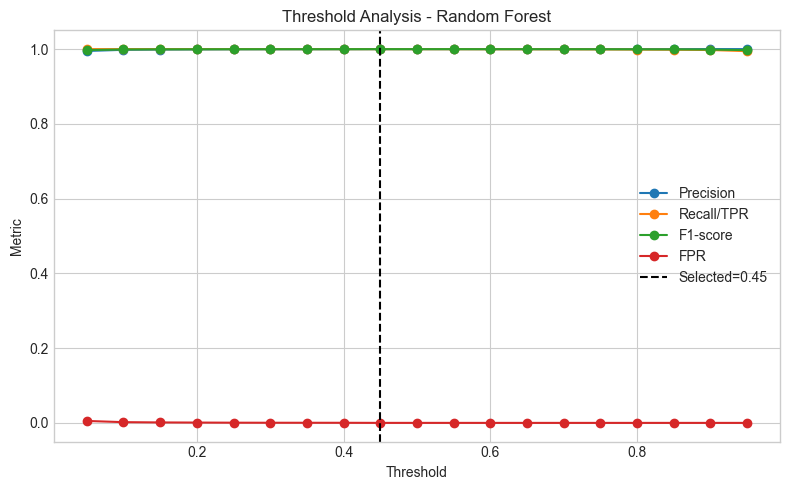

Saved: D:\Skripsi\doh_exfiltration_skripsi\outputs\threshold_analysis.png


In [12]:
best_model_name = metrics_df.iloc[0]["model"]
best_record = next(record for record in evaluation_records if record["model"] == best_model_name)
best_model = trained_models[best_model_name]

threshold_rows = []
for threshold in np.round(np.arange(0.05, 1.00, 0.05), 2):
    y_pred_threshold = (best_record["y_score"] >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred_threshold, labels=[0, 1]).ravel()
    threshold_rows.append({
        "threshold": threshold,
        "accuracy": accuracy_score(y_test, y_pred_threshold),
        "precision": precision_score(y_test, y_pred_threshold, zero_division=0),
        "recall_tpr": recall_score(y_test, y_pred_threshold, zero_division=0),
        "f1_score": f1_score(y_test, y_pred_threshold, zero_division=0),
        "fpr": fp / (fp + tn) if (fp + tn) else 0.0,
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp),
    })

threshold_df = pd.DataFrame(threshold_rows)
selected_threshold_row = threshold_df.sort_values(
    by=["f1_score", "fpr", "recall_tpr", "precision"],
    ascending=[False, True, False, False]
).iloc[0]
selected_threshold = float(selected_threshold_row["threshold"])

display(threshold_df)
print(f"Best model berdasarkan ROC-AUC/F1/Recall: {best_model_name}")
print(f"Threshold terpilih berdasarkan F1/Recall/Precision: {selected_threshold:.2f}")

plt.figure(figsize=(8, 5))
plt.plot(threshold_df["threshold"], threshold_df["precision"], marker="o", label="Precision")
plt.plot(threshold_df["threshold"], threshold_df["recall_tpr"], marker="o", label="Recall/TPR")
plt.plot(threshold_df["threshold"], threshold_df["f1_score"], marker="o", label="F1-score")
plt.plot(threshold_df["threshold"], threshold_df["fpr"], marker="o", label="FPR")
plt.axvline(selected_threshold, linestyle="--", color="black", label=f"Selected={selected_threshold:.2f}")
plt.xlabel("Threshold")
plt.ylabel("Metric")
plt.title(f"Threshold Analysis - {best_model_name}")
plt.legend()
plt.tight_layout()
threshold_path = OUTPUT_DIR / "threshold_analysis.png"
plt.savefig(threshold_path, dpi=160, bbox_inches="tight")
plt.show()
print(f"Saved: {threshold_path.resolve()}")

## 13. Simulasi Alert SOC Sederhana

In [13]:
soc_simulation = X_test.copy().reset_index(drop=True)
soc_simulation["actual_label"] = y_test.reset_index(drop=True).map({0: negative_class, 1: positive_class})
soc_simulation["malicious_probability"] = best_record["y_score"]
soc_simulation["alert"] = soc_simulation["malicious_probability"] >= selected_threshold
soc_simulation["severity"] = pd.cut(
    soc_simulation["malicious_probability"],
    bins=[-0.01, 0.50, 0.75, 0.90, 1.01],
    labels=["low", "medium", "high", "critical"],
)
soc_simulation["soc_action"] = np.select(
    [
        soc_simulation["severity"].eq("critical") & soc_simulation["alert"],
        soc_simulation["severity"].eq("high") & soc_simulation["alert"],
        soc_simulation["severity"].eq("medium") & soc_simulation["alert"],
    ],
    [
        "prioritize investigation and validate with SOC context",
        "create investigation ticket",
        "monitor flow and enrich context",
    ],
    default="no alert",
)

alert_summary = soc_simulation.groupby(["alert", "severity", "soc_action"], observed=True).size().reset_index(name="count")
top_alerts = soc_simulation.sort_values("malicious_probability", ascending=False).head(20)

display(alert_summary)
display(top_alerts[["actual_label", "malicious_probability", "alert", "severity", "soc_action"] + numeric_features[:5]])

soc_alerts_path = OUTPUT_DIR / "soc_alert_simulation.csv"
soc_simulation.to_csv(soc_alerts_path, index=False)
print(f"Saved: {soc_alerts_path.resolve()}")

,alert,severity,soc_action,count
0,False,low,no alert,48498
1,True,low,no alert,2
2,True,medium,monitor flow and enrich context,35
3,True,high,create investigation ticket,89
4,True,critical,prioritize investigation and validate with SOC...,49775


,actual_label,malicious_probability,alert,severity,soc_action,FlowBytesSent,FlowSentRate,FlowBytesReceived,FlowReceivedRate,PacketLengthVariance
98398,Malicious,1.0,True,critical,prioritize investigation and validate with SOC...,1876,55.621271,4827,143.115071,130110.978889
0,Malicious,1.0,True,critical,prioritize investigation and validate with SOC...,379563,7753.233103,525101,10726.099371,10483.711402
98397,Malicious,1.0,True,critical,prioritize investigation and validate with SOC...,1085,1324.912507,4032,4923.545832,224634.645062
98395,Malicious,1.0,True,critical,prioritize investigation and validate with SOC...,1806,53.022705,4897,143.771975,141598.912222
3,Malicious,1.0,True,critical,prioritize investigation and validate with SOC...,1807,52.962983,4896,143.501253,141502.778889
4,Malicious,1.0,True,critical,prioritize investigation and validate with SOC...,57291,477.387696,266035,2216.785110,251543.083694
98394,Malicious,1.0,True,critical,prioritize investigation and validate with SOC...,1807,53.665611,4828,143.385483,145520.370987
98373,Malicious,1.0,True,critical,prioritize investigation and validate with SOC...,137524,2605.149742,236336,4476.968888,16272.033400
98371,Malicious,1.0,True,critical,prioritize investigation and validate with SOC...,6469,53.639137,11206,92.917015,4904.526033
98365,Malicious,1.0,True,critical,prioritize investigation and validate with SOC...,1807,53.058478,4828,141.763326,145520.370987


Saved: D:\Skripsi\doh_exfiltration_skripsi\outputs\soc_alert_simulation.csv


## 14. Simpan Best Model dan Artefak Eksperimen

In [14]:
model_artifact = {
    "model": best_model,
    "model_name": best_model_name,
    "selected_threshold": selected_threshold,
    "numeric_features": numeric_features,
    "label_column": LABEL_COL,
    "negative_class_0": negative_class,
    "positive_class_1": positive_class,
}

best_model_path = OUTPUT_DIR / "best_model.pkl"
best_model_info_path = OUTPUT_DIR / "best_model_info.json"
experiment_report_path = OUTPUT_DIR / "experiment_report.txt"
metrics_path = OUTPUT_DIR / "model_metrics.csv"
threshold_metrics_path = OUTPUT_DIR / "threshold_analysis.csv"
feature_importance_csv_path = OUTPUT_DIR / "random_forest_feature_importance.csv"

joblib.dump(model_artifact, best_model_path)
metrics_df.to_csv(metrics_path, index=False)
threshold_df.to_csv(threshold_metrics_path, index=False)
feature_importance_df.to_csv(feature_importance_csv_path, index=False)

def to_jsonable(value):
    if isinstance(value, dict):
        return {str(key): to_jsonable(item) for key, item in value.items()}
    if isinstance(value, list):
        return [to_jsonable(item) for item in value]
    if isinstance(value, tuple):
        return [to_jsonable(item) for item in value]
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, np.floating):
        return float(value)
    if isinstance(value, np.ndarray):
        return value.tolist()
    return value


best_model_info = {
    "dataset_path": str(DATA_PATH),
    "output_dir": str(OUTPUT_DIR),
    "label_column": LABEL_COL,
    "negative_class_0": negative_class,
    "positive_class_1": positive_class,
    "numeric_features": numeric_features,
    "test_size": TEST_SIZE,
    "random_state": RANDOM_STATE,
    "best_model_name": best_model_name,
    "selected_threshold": selected_threshold,
    "cleaning_summary": cleaning_summary,
    "best_model_metrics_default_threshold": metrics_df[metrics_df["model"] == best_model_name].iloc[0].to_dict(),
    "selected_threshold_metrics": selected_threshold_row.to_dict(),
    "artifact_files": {
        "best_model": str(best_model_path),
        "metrics_csv": str(metrics_path),
        "threshold_csv": str(threshold_metrics_path),
        "feature_importance_csv": str(feature_importance_csv_path),
        "soc_alerts_csv": str(soc_alerts_path),
        "confusion_matrices_png": str(confusion_matrix_path),
        "roc_curve_png": str(roc_curve_path),
        "feature_importance_png": str(feature_importance_path),
        "threshold_analysis_png": str(threshold_path),
    },
}

with best_model_info_path.open("w", encoding="utf-8") as file:
    json.dump(to_jsonable(best_model_info), file, indent=2)

report_lines = [
    "DoH Exfiltration Detection - Metadata Flow Experiment Report",
    "=" * 68,
    f"Dataset              : {DATA_PATH}",
    f"Rows after cleaning  : {len(df):,}",
    f"Numeric features     : {len(numeric_features)}",
    f"Label column         : {LABEL_COL}",
    f"Negative class (0)   : {negative_class}",
    f"Positive class (1)   : {positive_class}",
    "",
    "Model Metrics at Default Threshold 0.50",
    metrics_df.to_string(index=False),
    "",
    f"Best model           : {best_model_name}",
    f"Selected threshold   : {selected_threshold:.2f}",
    "",
    "Selected Threshold Metrics",
    selected_threshold_row.to_frame().T.to_string(index=False),
    "",
    "Top 10 Random Forest Feature Importance",
    feature_importance_df.head(10).to_string(index=False),
    "",
    "SOC Alert Simulation Summary",
    alert_summary.to_string(index=False),
    "",
        "Methodological Notes",
        "-" * 60,
        "- Dataset publik digunakan karena penelitian tidak memiliki akses terhadap trafik SOC operasional nyata.",
        "- Kelas Malicious digunakan sebagai proksi trafik DoH berbahaya yang relevan dengan skenario eksfiltrasi/tunneling.",
        "- Model hanya menggunakan metadata flow numerik dan tidak melakukan dekripsi payload.",
        "- Simulasi alert SOC merupakan proof of concept offline, bukan sistem deteksi real-time.",
        "- Hasil pada dataset publik seimbang belum tentu langsung merepresentasikan performa pada jaringan operasional nyata.",
]


experiment_report_path.write_text("\n".join(report_lines), encoding="utf-8")

print(f"Saved: {best_model_path.resolve()}")
print(f"Saved: {best_model_info_path.resolve()}")
print(f"Saved: {experiment_report_path.resolve()}")
print(f"Saved: {metrics_path.resolve()}")

Saved: D:\Skripsi\doh_exfiltration_skripsi\outputs\best_model.pkl
Saved: D:\Skripsi\doh_exfiltration_skripsi\outputs\best_model_info.json
Saved: D:\Skripsi\doh_exfiltration_skripsi\outputs\experiment_report.txt
Saved: D:\Skripsi\doh_exfiltration_skripsi\outputs\model_metrics.csv


## 15. Advanced Evaluation Metrics

Metrik tambahan untuk membaca performa model dari sudut pandang SOC: false positive rate, specificity, NPV, MCC, balanced accuracy, dan average precision.

In [15]:
from sklearn.metrics import (
    average_precision_score,
    balanced_accuracy_score,
    matthews_corrcoef,
)

advanced_metric_rows = []
for record in evaluation_records:
    y_score = record["y_score"]
    y_pred = (y_score >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred, labels=[0, 1]).ravel()
    specificity = tn / (tn + fp) if (tn + fp) else 0.0
    npv = tn / (tn + fn) if (tn + fn) else 0.0
    fdr = fp / (fp + tp) if (fp + tp) else 0.0

    advanced_metric_rows.append({
        "model": record["model"],
        "balanced_accuracy": balanced_accuracy_score(y_test, y_pred),
        "average_precision": average_precision_score(y_test, y_score),
        "mcc": matthews_corrcoef(y_test, y_pred),
        "specificity_tnr": specificity,
        "negative_predictive_value": npv,
        "false_discovery_rate": fdr,
        "false_positive_rate": record["fpr"],
        "false_negative_count": int(fn),
        "false_positive_count": int(fp),
    })

advanced_metrics_df = pd.DataFrame(advanced_metric_rows).sort_values(
    by=["average_precision", "mcc", "balanced_accuracy"],
    ascending=False,
).reset_index(drop=True)

display(advanced_metrics_df)

advanced_metrics_path = OUTPUT_DIR / "advanced_evaluation_metrics.csv"
advanced_metrics_df.to_csv(advanced_metrics_path, index=False)
print(f"Saved: {advanced_metrics_path.resolve()}")

,model,balanced_accuracy,average_precision,mcc,specificity_tnr,negative_predictive_value,false_discovery_rate,false_positive_rate,false_negative_count,false_positive_count
0,Random Forest,0.999869,0.999999,0.999736,0.999959,0.999773,0.000040,0.000041,11,2
1,AdaBoost,0.998266,0.999961,0.996524,0.998556,0.997918,0.001403,0.001444,101,70
2,Logistic Regression,0.900762,0.953172,0.805058,0.859190,0.935385,0.126778,0.140810,2878,6828


Saved: D:\Skripsi\doh_exfiltration_skripsi\outputs\advanced_evaluation_metrics.csv


## 16. Resource Profiling Sederhana

Profil ringan untuk estimasi waktu inferensi, throughput, dan peak memory saat model terbaik melakukan prediksi pada test set.

In [16]:
import gc
import tracemalloc

gc.collect()
tracemalloc.start()
profile_start = time.perf_counter()
profile_scores = get_positive_scores(best_model, X_test)
profile_predictions = (profile_scores >= selected_threshold).astype(int)
profile_elapsed_sec = time.perf_counter() - profile_start
current_memory, peak_memory = tracemalloc.get_traced_memory()
tracemalloc.stop()

resource_profile = {
    "model": best_model_name,
    "rows_profiled": int(len(X_test)),
    "threshold": selected_threshold,
    "inference_time_sec": profile_elapsed_sec,
    "throughput_rows_per_sec": len(X_test) / profile_elapsed_sec if profile_elapsed_sec > 0 else np.inf,
    "peak_memory_mb": peak_memory / (1024 ** 2),
    "predicted_alerts": int(profile_predictions.sum()),
}
resource_profile_df = pd.DataFrame([resource_profile])
display(resource_profile_df)

resource_profile_path = OUTPUT_DIR / "resource_profile_simple.csv"
resource_profile_df.to_csv(resource_profile_path, index=False)
print(f"Saved: {resource_profile_path.resolve()}")

,model,rows_profiled,threshold,inference_time_sec,throughput_rows_per_sec,peak_memory_mb,predicted_alerts
0,Random Forest,98399,0.45,0.385581,255196.636965,51.268035,49901


Saved: D:\Skripsi\doh_exfiltration_skripsi\outputs\resource_profile_simple.csv


## 17. Cross-Validation / Stability Check

Validasi stabilitas performa menggunakan Stratified K-Fold pada model terbaik, tanpa mengubah split test utama.

In [22]:
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_scoring = {
    "roc_auc": "roc_auc",
    "f1": "f1",
    "recall": "recall",
    "precision": "precision",
    "balanced_accuracy": "balanced_accuracy",
}

cv_result = cross_validate(
    clone(best_model),
    X,
    y,
    cv=cv,
    scoring=cv_scoring,
    n_jobs=-1,
    return_train_score=False,
)

cv_summary_rows = []
for metric_name in cv_scoring:
    values = cv_result[f"test_{metric_name}"]
    cv_summary_rows.append({
        "metric": metric_name,
        "mean": float(np.mean(values)),
        "std": float(np.std(values)),
        "min": float(np.min(values)),
        "max": float(np.max(values)),
    })

cv_summary_df = pd.DataFrame(cv_summary_rows)
display(cv_summary_df)

cv_summary_path = OUTPUT_DIR / "cross_validation_stability.csv"
cv_summary_df.to_csv(cv_summary_path, index=False)
print(f"Saved: {cv_summary_path.resolve()}")

,metric,mean,std,min,max
0,roc_auc,1.000000,1.052734e-07,1.000000,1.00000
1,f1,0.999876,2.876006e-05,0.999840,0.99992
2,recall,0.999824,5.435834e-05,0.999740,0.99990
3,precision,0.999928,5.610171e-05,0.999860,0.99998
4,balanced_accuracy,0.999875,2.921107e-05,0.999838,0.99992


Saved: D:\Skripsi\doh_exfiltration_skripsi\outputs\cross_validation_stability.csv


## 18. Lightweight GridSearchCV Trial

Trial tuning ringan untuk Random Forest sebagai pembanding cepat, dibatasi pada grid kecil agar tidak menjadi eksperimen besar.

In [25]:
from sklearn.model_selection import GridSearchCV

lightweight_rf_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", RandomForestClassifier(
        random_state=RANDOM_STATE,
        class_weight="balanced",
        n_jobs=-1,
    )),
])

lightweight_grid = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [None, 12],
    "classifier__min_samples_leaf": [1, 3],
}

grid_search = GridSearchCV(
    lightweight_rf_pipeline,
    param_grid=lightweight_grid,
    scoring="roc_auc",
    cv=3,
    n_jobs=-1,
    refit=True,
)
grid_search.fit(X_train, y_train)

grid_results_df = pd.DataFrame(grid_search.cv_results_).sort_values(
    "rank_test_score"
)[[
    "rank_test_score",
    "mean_test_score",
    "std_test_score",
    "param_classifier__n_estimators",
    "param_classifier__max_depth",
    "param_classifier__min_samples_leaf",
]]

lightweight_grid_best_model = grid_search.best_estimator_
lightweight_grid_scores = get_positive_scores(lightweight_grid_best_model, X_test)
lightweight_grid_pred = (lightweight_grid_scores >= 0.5).astype(int)
lightweight_grid_summary = {
    "best_params": grid_search.best_params_,
    "cv_best_roc_auc": float(grid_search.best_score_),
    "test_roc_auc": roc_auc_score(y_test, lightweight_grid_scores),
    "test_f1_default_threshold": f1_score(y_test, lightweight_grid_pred, zero_division=0),
    "test_recall_default_threshold": recall_score(y_test, lightweight_grid_pred, zero_division=0),
    "test_precision_default_threshold": precision_score(y_test, lightweight_grid_pred, zero_division=0),
}

display(grid_results_df)
display(pd.DataFrame([lightweight_grid_summary]))

grid_results_path = OUTPUT_DIR / "lightweight_gridsearch_results.csv"
grid_summary_path = OUTPUT_DIR / "lightweight_gridsearch_summary.json"
grid_results_df.to_csv(grid_results_path, index=False)
with grid_summary_path.open("w", encoding="utf-8") as file:
    json.dump(to_jsonable(lightweight_grid_summary), file, indent=2)
print(f"Saved: {grid_results_path.resolve()}")
print(f"Saved: {grid_summary_path.resolve()}")

,rank_test_score,mean_test_score,std_test_score,param_classifier__n_estimators,param_classifier__max_depth,param_classifier__min_samples_leaf
1,1,1.000000,3.238693e-08,200,None,1
0,2,1.000000,3.337139e-08,100,None,1
3,3,1.000000,4.465144e-08,200,None,3
2,4,1.000000,5.296995e-08,100,None,3
5,5,0.999999,4.081888e-08,200,12,1
4,6,0.999999,3.947246e-08,100,12,1
6,7,0.999999,1.448123e-07,100,12,3
7,8,0.999999,1.756975e-07,200,12,3


,best_params,cv_best_roc_auc,test_roc_auc,test_f1_default_threshold,test_recall_default_threshold,test_precision_default_threshold
0,"{'classifier__max_depth': None, 'classifier__m...",1.0,0.999999,0.99987,0.99978,0.99996


Saved: D:\Skripsi\doh_exfiltration_skripsi\outputs\lightweight_gridsearch_results.csv
Saved: D:\Skripsi\doh_exfiltration_skripsi\outputs\lightweight_gridsearch_summary.json


## 19. Explainability Trial: SHAP atau Permutation Importance

Trial explainability: gunakan SHAP bila tersedia, lalu fallback ke permutation importance agar notebook tetap dapat berjalan di environment minimal.

SHAP tidak digunakan: No module named 'shap'


,feature,mean_abs_importance,importance_std,method
0,PacketLengthMode,8.352976e-02,8.855230e-03,permutation_importance
1,PacketLengthMedian,1.796076e-03,2.429427e-04,permutation_importance
2,ResponseTimeTimeMedian,1.001157e-05,7.163699e-06,permutation_importance
3,PacketLengthMean,4.440892e-17,5.438960e-17,permutation_importance
4,PacketTimeMode,2.220446e-17,4.440892e-17,permutation_importance
5,ResponseTimeTimeStandardDeviation,2.220446e-17,4.440892e-17,permutation_importance
6,PacketTimeMean,2.220446e-17,4.440892e-17,permutation_importance
7,PacketLengthSkewFromMedian,2.220446e-17,4.440892e-17,permutation_importance
8,FlowReceivedRate,0.000000e+00,0.000000e+00,permutation_importance
9,FlowBytesReceived,0.000000e+00,0.000000e+00,permutation_importance


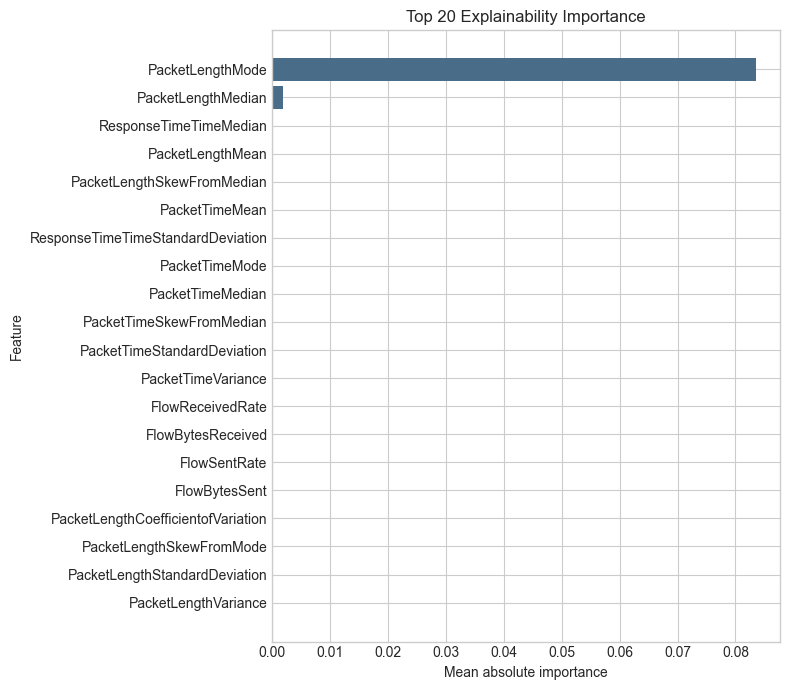

Saved: D:\Skripsi\doh_exfiltration_skripsi\outputs\explainability_importance.csv
Saved: D:\Skripsi\doh_exfiltration_skripsi\outputs\explainability_importance.png


In [27]:
from sklearn.inspection import permutation_importance

explainability_sample_size = min(1000, len(X_test))
X_explain = X_test.sample(explainability_sample_size, random_state=RANDOM_STATE)
y_explain = y_test.loc[X_explain.index]

try:
    import shap

    transformed_explain = best_model.named_steps["imputer"].transform(X_explain)
    classifier = best_model.named_steps["classifier"]
    explainer = shap.TreeExplainer(classifier)
    shap_values = explainer.shap_values(transformed_explain)
    shap_array = shap_values[1] if isinstance(shap_values, list) else shap_values
    explainability_df = pd.DataFrame({
        "feature": numeric_features,
        "mean_abs_importance": np.abs(shap_array).mean(axis=0),
        "method": "shap_tree_explainer",
    }).sort_values("mean_abs_importance", ascending=False).reset_index(drop=True)
except Exception as shap_error:
    print(f"SHAP tidak digunakan: {shap_error}")
    permutation_result = permutation_importance(
        best_model,
        X_explain,
        y_explain,
        n_repeats=5,
        random_state=RANDOM_STATE,
        scoring="roc_auc",
        n_jobs=-1,
    )
    explainability_df = pd.DataFrame({
        "feature": numeric_features,
        "mean_abs_importance": permutation_result.importances_mean,
        "importance_std": permutation_result.importances_std,
        "method": "permutation_importance",
    }).sort_values("mean_abs_importance", ascending=False).reset_index(drop=True)

display(explainability_df.head(20))

plt.figure(figsize=(8, 7))
plot_explainability = explainability_df.head(20).sort_values("mean_abs_importance")
plt.barh(plot_explainability["feature"], plot_explainability["mean_abs_importance"], color="#496d89")
plt.title("Top 20 Explainability Importance")
plt.xlabel("Mean absolute importance")
plt.ylabel("Feature")
plt.tight_layout()

explainability_path = OUTPUT_DIR / "explainability_importance.csv"
explainability_plot_path = OUTPUT_DIR / "explainability_importance.png"
explainability_df.to_csv(explainability_path, index=False)
plt.savefig(explainability_plot_path, dpi=160, bbox_inches="tight")
plt.show()
print(f"Saved: {explainability_path.resolve()}")
print(f"Saved: {explainability_plot_path.resolve()}")

## 20. Enhanced Threshold Analysis

Analisis threshold yang lebih rinci untuk melihat trade-off recall, FPR, alert volume, dan skor utilitas sederhana.

,threshold,precision,recall_tpr,f1_score,specificity_tnr,fpr,alert_volume,alert_rate,utility_score,tn,fp,fn,tp
0,0.01,0.965226,1.000000,0.982306,0.962921,0.037079,51706,0.525473,2.853989,46693,1798,0,49908
1,0.02,0.983912,0.999960,0.991871,0.983172,0.016828,50722,0.515473,2.933349,47675,816,2,49906
2,0.03,0.989904,0.999940,0.994896,0.989503,0.010497,50414,0.512343,2.958293,47982,509,3,49905
3,0.04,0.992996,0.999940,0.996456,0.992741,0.007259,50257,0.510747,2.971099,48139,352,3,49905
4,0.05,0.994976,0.999940,0.997452,0.994803,0.005197,50157,0.509731,2.979265,48239,252,3,49905
...,...,...,...,...,...,...,...,...,...,...,...,...,...
94,0.95,1.000000,0.994550,0.997268,1.000000,0.000000,49636,0.504436,2.989100,48491,0,272,49636
95,0.96,1.000000,0.993027,0.996501,1.000000,0.000000,49560,0.503664,2.986054,48491,0,348,49560
96,0.97,1.000000,0.990703,0.995330,1.000000,0.000000,49444,0.502485,2.981406,48491,0,464,49444
97,0.98,1.000000,0.986455,0.993181,1.000000,0.000000,49232,0.500330,2.972910,48491,0,676,49232


Enhanced threshold terpilih: 0.45


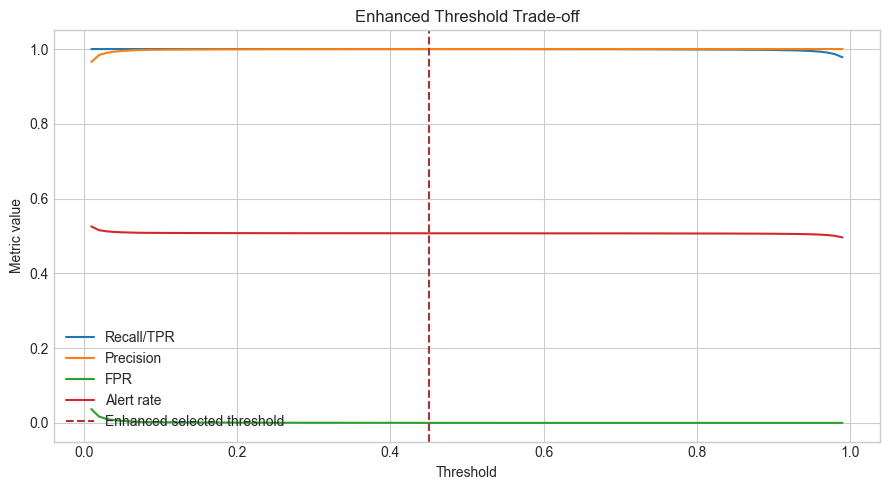

Saved: D:\Skripsi\doh_exfiltration_skripsi\outputs\enhanced_threshold_analysis.csv
Saved: D:\Skripsi\doh_exfiltration_skripsi\outputs\enhanced_threshold_analysis.png


In [17]:
enhanced_threshold_rows = []
for threshold in np.round(np.arange(0.01, 1.00, 0.01), 2):
    y_pred_threshold = (best_record["y_score"] >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred_threshold, labels=[0, 1]).ravel()
    precision = precision_score(y_test, y_pred_threshold, zero_division=0)
    recall = recall_score(y_test, y_pred_threshold, zero_division=0)
    fpr_value = fp / (fp + tn) if (fp + tn) else 0.0
    alert_volume = int(tp + fp)
    utility_score = (2.0 * recall) + precision - (3.0 * fpr_value)

    enhanced_threshold_rows.append({
        "threshold": threshold,
        "precision": precision,
        "recall_tpr": recall,
        "f1_score": f1_score(y_test, y_pred_threshold, zero_division=0),
        "specificity_tnr": tn / (tn + fp) if (tn + fp) else 0.0,
        "fpr": fpr_value,
        "alert_volume": alert_volume,
        "alert_rate": alert_volume / len(y_test),
        "utility_score": utility_score,
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp),
    })

enhanced_threshold_df = pd.DataFrame(enhanced_threshold_rows)
enhanced_selected_threshold_row = enhanced_threshold_df.sort_values(
    by=["utility_score", "f1_score", "recall_tpr"],
    ascending=False,
).iloc[0]
enhanced_selected_threshold = float(enhanced_selected_threshold_row["threshold"])

display(enhanced_threshold_df)
print(f"Enhanced threshold terpilih: {enhanced_selected_threshold:.2f}")

plt.figure(figsize=(9, 5))
plt.plot(enhanced_threshold_df["threshold"], enhanced_threshold_df["recall_tpr"], label="Recall/TPR")
plt.plot(enhanced_threshold_df["threshold"], enhanced_threshold_df["precision"], label="Precision")
plt.plot(enhanced_threshold_df["threshold"], enhanced_threshold_df["fpr"], label="FPR")
plt.plot(enhanced_threshold_df["threshold"], enhanced_threshold_df["alert_rate"], label="Alert rate")
plt.axvline(enhanced_selected_threshold, color="#a33", linestyle="--", label="Enhanced selected threshold")
plt.title("Enhanced Threshold Trade-off")
plt.xlabel("Threshold")
plt.ylabel("Metric value")
plt.legend()
plt.tight_layout()

enhanced_threshold_path = OUTPUT_DIR / "enhanced_threshold_analysis.csv"
enhanced_threshold_plot_path = OUTPUT_DIR / "enhanced_threshold_analysis.png"
enhanced_threshold_df.to_csv(enhanced_threshold_path, index=False)
plt.savefig(enhanced_threshold_plot_path, dpi=160, bbox_inches="tight")
plt.show()
print(f"Saved: {enhanced_threshold_path.resolve()}")
print(f"Saved: {enhanced_threshold_plot_path.resolve()}")

## 21. Environment Comparison Summary

Ringkasan perbandingan antara eksperimen dataset publik/offline dan target penerapan SOC operasional.

In [18]:
environment_comparison_rows = [
    {
        "aspect": "Data source",
        "current_experiment": "Public/offline dataset",
        "target_soc_environment": "Live resolver, proxy, EDR, DNS, and network telemetry",
        "risk_or_gap": "Distribusi trafik produksi dapat berbeda dari dataset penelitian",
        "mitigation": "Validasi ulang dengan telemetry lokal dan holdout temporal",
    },
    {
        "aspect": "Label quality",
        "current_experiment": "Dataset label digunakan sebagai ground truth",
        "target_soc_environment": "Label berasal dari triage analyst, threat intel, dan incident closure",
        "risk_or_gap": "Label operasional bisa noisy atau terlambat",
        "mitigation": "Gunakan feedback loop dan periodic relabeling",
    },
    {
        "aspect": "Feature scope",
        "current_experiment": "Metadata flow numerik",
        "target_soc_environment": "Metadata flow ditambah host, user, ASN, JA3/JA4, dan policy context",
        "risk_or_gap": "Konteks SOC belum lengkap di model ini",
        "mitigation": "Tambahkan enrichment non-payload secara bertahap",
    },
    {
        "aspect": "Latency",
        "current_experiment": "Batch notebook",
        "target_soc_environment": "Near-real-time scoring",
        "risk_or_gap": "Kebutuhan throughput belum diuji end-to-end",
        "mitigation": "Load test pipeline scoring dan alert delivery",
    },
    {
        "aspect": "Alert handling",
        "current_experiment": "Simulasi alert sederhana",
        "target_soc_environment": "Case management dengan deduplication dan suppression",
        "risk_or_gap": "Alert fatigue jika threshold terlalu agresif",
        "mitigation": "Gunakan threshold berbasis kapasitas SOC dan severity routing",
    },
]

environment_comparison_df = pd.DataFrame(environment_comparison_rows)
display(environment_comparison_df)

environment_comparison_path = OUTPUT_DIR / "environment_comparison_summary.csv"
environment_comparison_df.to_csv(environment_comparison_path, index=False)
print(f"Saved: {environment_comparison_path.resolve()}")

,aspect,current_experiment,target_soc_environment,risk_or_gap,mitigation
0,Data source,Public/offline dataset,"Live resolver, proxy, EDR, DNS, and network te...",Distribusi trafik produksi dapat berbeda dari ...,Validasi ulang dengan telemetry lokal dan hold...
1,Label quality,Dataset label digunakan sebagai ground truth,"Label berasal dari triage analyst, threat inte...",Label operasional bisa noisy atau terlambat,Gunakan feedback loop dan periodic relabeling
2,Feature scope,Metadata flow numerik,"Metadata flow ditambah host, user, ASN, JA3/JA...",Konteks SOC belum lengkap di model ini,Tambahkan enrichment non-payload secara bertahap
3,Latency,Batch notebook,Near-real-time scoring,Kebutuhan throughput belum diuji end-to-end,Load test pipeline scoring dan alert delivery
4,Alert handling,Simulasi alert sederhana,Case management dengan deduplication dan suppr...,Alert fatigue jika threshold terlalu agresif,Gunakan threshold berbasis kapasitas SOC dan s...


Saved: D:\Skripsi\doh_exfiltration_skripsi\outputs\environment_comparison_summary.csv


## 22. Enhanced SOC Alert Summary

Versi ringkasan alert yang diperkaya dengan prioritas investigasi, alasan triage, dan rekomendasi langkah SOC.

In [19]:
enhanced_soc_alerts = soc_simulation.copy()
enhanced_soc_alerts["enhanced_alert"] = enhanced_soc_alerts["malicious_probability"] >= enhanced_selected_threshold
enhanced_soc_alerts["priority"] = pd.cut(
    enhanced_soc_alerts["malicious_probability"],
    bins=[-0.01, 0.50, 0.75, 0.90, 1.01],
    labels=["P4", "P3", "P2", "P1"],
)
enhanced_soc_alerts["triage_reason"] = np.select(
    [
        enhanced_soc_alerts["malicious_probability"].ge(0.90),
        enhanced_soc_alerts["malicious_probability"].ge(0.75),
        enhanced_soc_alerts["malicious_probability"].ge(enhanced_selected_threshold),
    ],
    [
        "very high model confidence",
        "high model confidence",
        "above enhanced operating threshold",
    ],
    default="below enhanced operating threshold",
)
enhanced_soc_alerts["recommended_action"] = np.select(
    [
        enhanced_soc_alerts["priority"].astype(str).eq("P1") & enhanced_soc_alerts["enhanced_alert"],
        enhanced_soc_alerts["priority"].astype(str).eq("P2") & enhanced_soc_alerts["enhanced_alert"],
        enhanced_soc_alerts["enhanced_alert"],
    ],
    [
        "open incident and validate endpoint/network context",
        "create case and correlate with DNS/proxy logs",
        "queue for analyst review",
    ],
    default="suppress unless correlated with other signals",
)

enhanced_alert_summary = enhanced_soc_alerts.groupby(
    ["enhanced_alert", "priority", "triage_reason", "recommended_action"],
    observed=True,
).size().reset_index(name="count")

top_enhanced_alerts = enhanced_soc_alerts.sort_values(
    "malicious_probability", ascending=False
).head(25)

display(enhanced_alert_summary)
display(top_enhanced_alerts[[
    "actual_label",
    "malicious_probability",
    "enhanced_alert",
    "priority",
    "triage_reason",
    "recommended_action",
] + numeric_features[:5]])

enhanced_soc_alerts_path = OUTPUT_DIR / "enhanced_soc_alert_summary.csv"
top_enhanced_alerts_path = OUTPUT_DIR / "top_enhanced_soc_alerts.csv"
enhanced_alert_summary.to_csv(enhanced_soc_alerts_path, index=False)
top_enhanced_alerts.to_csv(top_enhanced_alerts_path, index=False)
print(f"Saved: {enhanced_soc_alerts_path.resolve()}")
print(f"Saved: {top_enhanced_alerts_path.resolve()}")

,enhanced_alert,priority,triage_reason,recommended_action,count
0,False,P4,below enhanced operating threshold,suppress unless correlated with other signals,48498
1,True,P4,above enhanced operating threshold,queue for analyst review,2
2,True,P3,above enhanced operating threshold,queue for analyst review,29
3,True,P3,high model confidence,queue for analyst review,6
4,True,P2,high model confidence,create case and correlate with DNS/proxy logs,79
5,True,P2,very high model confidence,create case and correlate with DNS/proxy logs,10
6,True,P1,very high model confidence,open incident and validate endpoint/network co...,49775


,actual_label,malicious_probability,enhanced_alert,priority,triage_reason,recommended_action,FlowBytesSent,FlowSentRate,FlowBytesReceived,FlowReceivedRate,PacketLengthVariance
98398,Malicious,1.0,True,P1,very high model confidence,open incident and validate endpoint/network co...,1876,55.621271,4827,143.115071,130110.978889
0,Malicious,1.0,True,P1,very high model confidence,open incident and validate endpoint/network co...,379563,7753.233103,525101,10726.099371,10483.711402
98397,Malicious,1.0,True,P1,very high model confidence,open incident and validate endpoint/network co...,1085,1324.912507,4032,4923.545832,224634.645062
98395,Malicious,1.0,True,P1,very high model confidence,open incident and validate endpoint/network co...,1806,53.022705,4897,143.771975,141598.912222
3,Malicious,1.0,True,P1,very high model confidence,open incident and validate endpoint/network co...,1807,52.962983,4896,143.501253,141502.778889
4,Malicious,1.0,True,P1,very high model confidence,open incident and validate endpoint/network co...,57291,477.387696,266035,2216.785110,251543.083694
98394,Malicious,1.0,True,P1,very high model confidence,open incident and validate endpoint/network co...,1807,53.665611,4828,143.385483,145520.370987
98373,Malicious,1.0,True,P1,very high model confidence,open incident and validate endpoint/network co...,137524,2605.149742,236336,4476.968888,16272.033400
98371,Malicious,1.0,True,P1,very high model confidence,open incident and validate endpoint/network co...,6469,53.639137,11206,92.917015,4904.526033
98365,Malicious,1.0,True,P1,very high model confidence,open incident and validate endpoint/network co...,1807,53.058478,4828,141.763326,145520.370987


Saved: D:\Skripsi\doh_exfiltration_skripsi\outputs\enhanced_soc_alert_summary.csv
Saved: D:\Skripsi\doh_exfiltration_skripsi\outputs\top_enhanced_soc_alerts.csv


## 23. Enriched Experiment Report

Laporan eksperimen yang menggabungkan hasil utama dengan enrichment evaluasi, profiling, stability check, threshold, explainability, dan ringkasan SOC.

In [28]:
# ============================================================
# 23. Enriched Experiment Report
# ============================================================

import json
from pathlib import Path
import pandas as pd
import numpy as np

# ------------------------------------------------------------
# Helper: aman untuk simpan JSON meskipun ada numpy/pandas object
# ------------------------------------------------------------
def safe_to_jsonable(obj):
    if isinstance(obj, (np.integer,)):
        return int(obj)
    if isinstance(obj, (np.floating,)):
        return float(obj)
    if isinstance(obj, (np.ndarray,)):
        return obj.tolist()
    if isinstance(obj, (pd.Series,)):
        return obj.to_dict()
    if isinstance(obj, (pd.DataFrame,)):
        return obj.to_dict(orient="records")
    if isinstance(obj, Path):
        return str(obj)
    if isinstance(obj, dict):
        return {k: safe_to_jsonable(v) for k, v in obj.items()}
    if isinstance(obj, list):
        return [safe_to_jsonable(v) for v in obj]
    return obj

# Kalau notebook sebelumnya sudah punya to_jsonable, tetap boleh dipakai.
# Kalau belum ada, pakai safe_to_jsonable.
if "to_jsonable" not in globals():
    to_jsonable = safe_to_jsonable

# ------------------------------------------------------------
# Fallback untuk section enriched yang opsional/berat
# Bagian ini penting karena section 17, 18, 19 boleh belum dijalankan.
# ------------------------------------------------------------

# Cross-validation fallback
if "cv_summary_df" not in globals():
    cv_summary_df = pd.DataFrame([{
        "status": "not_run",
        "note": "Cross-validation / stability check belum dijalankan pada sesi ini."
    }])

if "cv_summary_path" not in globals():
    cv_summary_path = OUTPUT_DIR / "cross_validation_stability_not_run.csv"
    cv_summary_df.to_csv(cv_summary_path, index=False)

# Lightweight GridSearch fallback
if "lightweight_grid_summary" not in globals():
    lightweight_grid_summary = {
        "status": "not_run",
        "note": "Lightweight GridSearchCV belum dijalankan pada sesi ini."
    }

if "grid_results_df" not in globals():
    grid_results_df = pd.DataFrame([lightweight_grid_summary])

if "grid_results_path" not in globals():
    grid_results_path = OUTPUT_DIR / "lightweight_gridsearch_results_not_run.csv"
    grid_results_df.to_csv(grid_results_path, index=False)

if "grid_summary_path" not in globals():
    grid_summary_path = OUTPUT_DIR / "lightweight_gridsearch_summary_not_run.json"
    with grid_summary_path.open("w", encoding="utf-8") as file:
        json.dump(to_jsonable(lightweight_grid_summary), file, indent=2)

# Explainability fallback
if "explainability_df" not in globals():
    explainability_df = pd.DataFrame([{
        "status": "not_run",
        "feature": None,
        "importance": None,
        "note": "Explainability trial SHAP/permutation importance belum dijalankan pada sesi ini."
    }])

if "explainability_path" not in globals():
    explainability_path = OUTPUT_DIR / "explainability_importance_not_run.csv"
    explainability_df.to_csv(explainability_path, index=False)

if "explainability_plot_path" not in globals():
    explainability_plot_path = OUTPUT_DIR / "explainability_importance_not_run.png"

# Advanced metrics fallback
if "advanced_metrics_df" not in globals():
    advanced_metrics_df = pd.DataFrame([{
        "status": "not_available",
        "note": "Advanced metrics belum tersedia pada sesi ini."
    }])

if "advanced_metrics_path" not in globals():
    advanced_metrics_path = OUTPUT_DIR / "advanced_evaluation_metrics_not_available.csv"
    advanced_metrics_df.to_csv(advanced_metrics_path, index=False)

# Resource profiling fallback
if "resource_profile" not in globals():
    resource_profile = {
        "status": "not_available",
        "note": "Resource profiling belum tersedia pada sesi ini."
    }

if "resource_profile_df" not in globals():
    resource_profile_df = pd.DataFrame([resource_profile])

if "resource_profile_path" not in globals():
    resource_profile_path = OUTPUT_DIR / "resource_profile_simple_not_available.csv"
    resource_profile_df.to_csv(resource_profile_path, index=False)

# Enhanced threshold fallback
if "enhanced_selected_threshold" not in globals():
    enhanced_selected_threshold = selected_threshold

if "enhanced_selected_threshold_row" not in globals():
    enhanced_selected_threshold_row = pd.Series({
        "status": "not_available",
        "note": "Enhanced threshold analysis belum tersedia pada sesi ini."
    })

if "enhanced_threshold_path" not in globals():
    enhanced_threshold_path = OUTPUT_DIR / "enhanced_threshold_analysis_not_available.csv"

if "enhanced_threshold_plot_path" not in globals():
    enhanced_threshold_plot_path = OUTPUT_DIR / "enhanced_threshold_analysis_not_available.png"

# Environment comparison fallback
if "environment_comparison_df" not in globals():
    environment_comparison_df = pd.DataFrame([{
        "status": "not_available",
        "note": "Environment comparison belum tersedia pada sesi ini."
    }])

if "environment_comparison_path" not in globals():
    environment_comparison_path = OUTPUT_DIR / "environment_comparison_summary_not_available.csv"
    environment_comparison_df.to_csv(environment_comparison_path, index=False)

# SOC alert fallback
if "enhanced_alert_summary" not in globals():
    enhanced_alert_summary = pd.DataFrame([{
        "status": "not_available",
        "note": "Enhanced SOC alert summary belum tersedia pada sesi ini."
    }])

if "enhanced_soc_alerts_path" not in globals():
    enhanced_soc_alerts_path = OUTPUT_DIR / "enhanced_soc_alert_summary_not_available.csv"
    enhanced_alert_summary.to_csv(enhanced_soc_alerts_path, index=False)

if "top_enhanced_alerts_path" not in globals():
    top_enhanced_alerts_path = OUTPUT_DIR / "top_enhanced_soc_alerts_not_available.csv"

# ------------------------------------------------------------
# Simpan enriched report dan JSON info
# ------------------------------------------------------------

enriched_report_path = OUTPUT_DIR / "enriched_experiment_report.txt"
enriched_model_info_path = OUTPUT_DIR / "enriched_experiment_info.json"

enriched_info = {
    "dataset_path": str(DATA_PATH),
    "output_dir": str(OUTPUT_DIR),
    "best_model_name": best_model_name,
    "default_selected_threshold": selected_threshold,
    "enhanced_selected_threshold": enhanced_selected_threshold,
    "advanced_metrics": advanced_metrics_df.to_dict(orient="records"),
    "resource_profile": resource_profile,
    "cv_summary": cv_summary_df.to_dict(orient="records"),
    "lightweight_gridsearch": lightweight_grid_summary,
    "enhanced_threshold_selected_metrics": enhanced_selected_threshold_row.to_dict(),
    "environment_comparison": environment_comparison_df.to_dict(orient="records"),
    "artifact_files": {
        "advanced_metrics_csv": str(advanced_metrics_path),
        "resource_profile_csv": str(resource_profile_path),
        "cross_validation_csv": str(cv_summary_path),
        "lightweight_gridsearch_csv": str(grid_results_path),
        "lightweight_gridsearch_json": str(grid_summary_path),
        "explainability_csv": str(explainability_path),
        "explainability_png": str(explainability_plot_path),
        "enhanced_threshold_csv": str(enhanced_threshold_path),
        "enhanced_threshold_png": str(enhanced_threshold_plot_path),
        "environment_comparison_csv": str(environment_comparison_path),
        "enhanced_soc_alert_summary_csv": str(enhanced_soc_alerts_path),
        "top_enhanced_soc_alerts_csv": str(top_enhanced_alerts_path),
        "enriched_report_txt": str(enriched_report_path),
        "enriched_info_json": str(enriched_model_info_path),
    },
    "methodological_notes": [
        "Dataset publik digunakan karena tidak tersedia akses trafik SOC operasional nyata.",
        "Kelas Malicious digunakan sebagai proksi trafik DoH berbahaya yang relevan dengan skenario eksfiltrasi/tunneling.",
        "Model hanya menggunakan metadata flow numerik dan tidak melakukan dekripsi payload.",
        "Simulasi alert SOC merupakan proof of concept offline, bukan sistem real-time.",
        "Hasil pada dataset publik belum tentu langsung merepresentasikan performa pada jaringan operasional nyata.",
        "Eksperimen berat seperti Cross-Validation, GridSearchCV, dan Explainability dapat dijalankan terpisah serta dicatat statusnya jika belum dijalankan.",
    ],
}

with enriched_model_info_path.open("w", encoding="utf-8") as file:
    json.dump(to_jsonable(enriched_info), file, indent=2)

enriched_report_lines = [
    "DoH Exfiltration Detection - Enriched Experiment Report",
    "=" * 68,
    f"Dataset                    : {DATA_PATH}",
    f"Rows after cleaning        : {len(df):,}",
    f"Numeric features           : {len(numeric_features)}",
    f"Best model                 : {best_model_name}",
    f"Default selected threshold : {selected_threshold:.2f}",
    f"Enhanced selected threshold: {enhanced_selected_threshold:.2f}",
    "",
    "Advanced Evaluation Metrics",
    advanced_metrics_df.to_string(index=False),
    "",
    "Resource Profiling",
    resource_profile_df.to_string(index=False),
    "",
    "Cross-Validation Stability",
    cv_summary_df.to_string(index=False),
    "",
    "Lightweight GridSearchCV Trial",
    pd.DataFrame([lightweight_grid_summary]).to_string(index=False),
    "",
    "Top 15 Explainability Features",
    explainability_df.head(15).to_string(index=False),
    "",
    "Enhanced Threshold Selected Metrics",
    enhanced_selected_threshold_row.to_frame().T.to_string(index=False),
    "",
    "Environment Comparison Summary",
    environment_comparison_df.to_string(index=False),
    "",
    "Enhanced SOC Alert Summary",
    enhanced_alert_summary.to_string(index=False),
    "",
    "Methodological Notes",
    "- Dataset publik digunakan karena tidak tersedia akses trafik SOC operasional nyata.",
    "- Kelas Malicious digunakan sebagai proksi trafik DoH berbahaya yang relevan dengan skenario eksfiltrasi/tunneling.",
    "- Model hanya menggunakan metadata flow numerik dan tidak melakukan dekripsi payload.",
    "- Simulasi alert SOC merupakan proof of concept offline, bukan sistem real-time.",
    "- Hasil pada dataset publik belum tentu langsung merepresentasikan performa pada jaringan operasional nyata.",
    "- Enrichment ini tidak menggantikan validasi produksi atau uji real-time.",
    "- Threshold perlu disesuaikan dengan kapasitas triage SOC dan toleransi false positive.",
    "- Explainability digunakan sebagai insight awal, bukan bukti kausal tunggal.",
    "- Section berat seperti Cross-Validation, GridSearchCV, dan Explainability dapat dijalankan terpisah serta dicatat statusnya.",
]

enriched_report_path.write_text("\n".join(enriched_report_lines), encoding="utf-8")

print(f"Saved: {enriched_report_path.resolve()}")
print(f"Saved: {enriched_model_info_path.resolve()}")

Saved: D:\Skripsi\doh_exfiltration_skripsi\outputs\enriched_experiment_report.txt
Saved: D:\Skripsi\doh_exfiltration_skripsi\outputs\enriched_experiment_info.json
